In [90]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [92]:
df = pd.read_csv('data/messages.csv',low_memory=False)
df.head(5)

,id,message_id,campaign_id,message_type,client_id,channel,category,platform,email_provider,stream,...,is_complained,complained_at,is_blocked,blocked_at,is_purchased,purchased_at,created_at,updated_at,user_device_id,user_id
0,3534616,ef8a528b-ca21-4776-bc01-7457c104c17d,179,transactional,1515915625489979831,email,NaN,NaN,mail.ru,desktop,...,f,NaN,f,NaN,f,NaN,2023-04-27 08:55:16.592921,2023-04-27 09:00:46.279486,1,548997983
1,3520796,b795c37c-c18d-4229-8519-23d92ceb7efc,26,transactional,1515915625536936087,email,NaN,NaN,mail.ru,desktop,...,f,NaN,f,NaN,f,NaN,2023-04-27 08:54:56.288191,2023-04-27 08:54:56.288742,7,553693608
2,3520922,023771ae-96d3-4110-9c08-304640cb3177,27,transactional,1515915625559165402,email,NaN,NaN,mail.ru,desktop,...,f,NaN,f,NaN,f,NaN,2023-04-27 08:54:56.470486,2023-04-27 08:56:09.120462,2,555916540
3,3520978,053e8b38-c168-4245-bac5-6ed63ebe7a12,27,transactional,1515915625499291557,email,NaN,NaN,mail.ru,desktop,...,f,NaN,f,NaN,f,NaN,2023-04-27 08:54:56.553462,2023-04-27 08:54:56.553999,7,549929155
4,3520981,058e974e-1830-492e-b77d-01f1b0ec4ea3,27,transactional,1515915625491921710,email,NaN,NaN,mail.ru,desktop,...,f,NaN,f,NaN,f,NaN,2023-04-27 08:54:56.557318,2023-04-27 08:54:56.557813,0,549192171


In [93]:
df.isna().sum()

id                             0
message_id                     0
campaign_id                    0
message_type                   0
client_id                      0
channel                        0
category                 2993736
platform                 2773103
email_provider           1267316
stream                         0
date                           0
sent_at                        0
is_opened                      0
opened_first_time_at     2510869
opened_last_time_at      2510869
is_clicked                     0
clicked_first_time_at    2923403
clicked_last_time_at     2923403
is_unsubscribed                0
unsubscribed_at          2902741
is_hard_bounced                0
hard_bounced_at          2984457
is_soft_bounced                0
soft_bounced_at          2992487
is_complained                  0
complained_at            2992224
is_blocked                     0
blocked_at               2993677
is_purchased                   0
purchased_at             2990067
created_at

In [100]:
df = df.drop('category',axis=1)

### Platform

In [104]:
# Calculating the platform distribution without NaN
platform_distribution = df["platform"].value_counts(normalize=True)

# Choosing random values based on the distribution
missing_platforms = np.random.choice(
    platform_distribution.index,  # Unique platform values
    size=df["platform"].isna().sum(),  # Number of passes
    p=platform_distribution.values  # Probabilities
)

# Filling in the missing values
df.loc[df["platform"].isna(), "platform"] = missing_platforms

### Email_provider

In [106]:
print(df["email_provider"].value_counts(dropna=False, normalize=True) * 100)

email_provider
NaN                 42.332256
mail.ru             31.737234
gmail.com           10.034318
yandex.ru            8.519956
bk.ru                2.550058
                      ...    
bashkortostan.ru     0.000033
nlstar.com           0.000033
naver.com            0.000033
jmail.ru             0.000033
inox.ru              0.000033
Name: proportion, Length: 177, dtype: float64


In [108]:
# Get a distribution without NaN
email_distribution = df["email_provider"].dropna().value_counts(normalize=True)

# Function for filling NaN values with random email_provider by distribution
def fill_email_provider(row):
    if pd.isna(row["email_provider"]):
        return np.random.choice(email_distribution.index, p=email_distribution.values)
    return row["email_provider"]

# Applying the function
df["email_provider"] = df.apply(fill_email_provider, axis=1)

In [109]:
print(df["email_provider"].value_counts(normalize=True))  # We check that the distribution has not changed much

email_provider
mail.ru             5.506280e-01
gmail.com           1.739355e-01
yandex.ru           1.478213e-01
bk.ru               4.412480e-02
list.ru             2.647762e-02
                        ...     
ozon.ru             3.340308e-07
bashkortostan.ru    3.340308e-07
nlstar.com          3.340308e-07
eist.ru             3.340308e-07
suek.ru             3.340308e-07
Name: proportion, Length: 176, dtype: float64


### Opened_First_Time

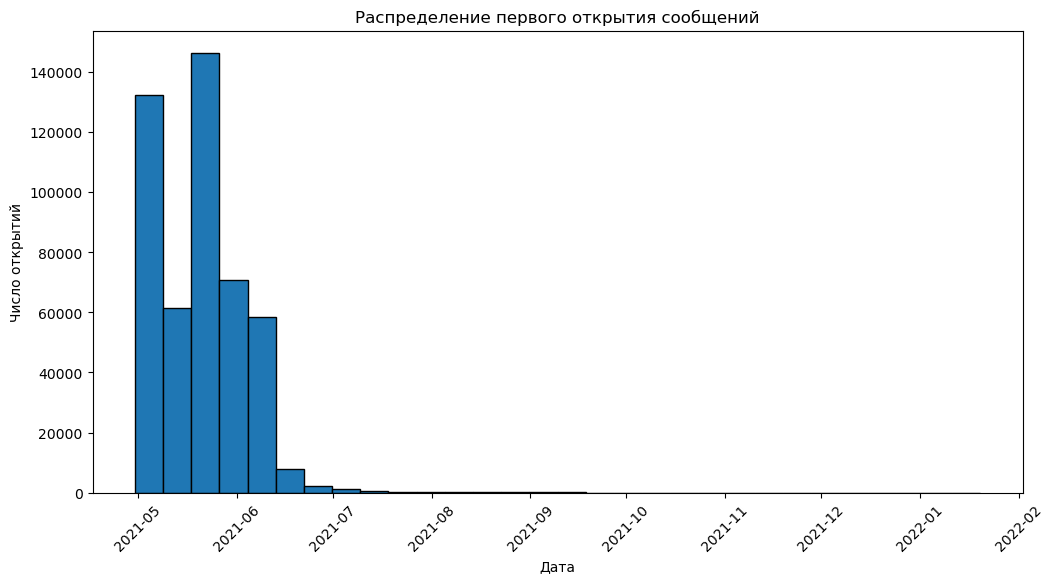

In [110]:
# Converting it to datetime, if you haven't already
df['opened_first_time_at'] = pd.to_datetime(df['opened_first_time_at'])

# Removing NaN
opened_times = df['opened_first_time_at'].dropna()

# We round it up to days to simplify the analysis
opened_times = opened_times.dt.date

plt.figure(figsize=(12, 6))
plt.hist(opened_times, bins=30, edgecolor='black')
plt.xticks(rotation=45)
plt.xlabel("Date")
plt.ylabel("Number of openings")
plt.title("Distribution of the first message opening")
plt.show()

In [112]:
datetime_columns = [
    "sent_at", "opened_first_time_at", "opened_last_time_at",
    "clicked_first_time_at", "clicked_last_time_at", "unsubscribed_at",
    "hard_bounced_at", "soft_bounced_at", "complained_at",
    "blocked_at", "purchased_at", "created_at", "updated_at"
]
for col in datetime_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

In [113]:
for col in datetime_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# Fill-in function NaN median value within the group
def fillna_group_median(df, group_col, target_col):
    return df[target_col].fillna(df.groupby(group_col)[target_col].transform("median"))

In [114]:
# Completion opened_first_time_at and opened_last_time_at
for col in ["opened_first_time_at", "opened_last_time_at"]:
    df[col] = fillna_group_median(df, "campaign_id", col)
    df[col] = df[col].fillna(df["sent_at"])  # If still NaN, we put sent_at

# Check, what opened_last_time_at >= opened_first_time_at
mask_opened_invalid = df["opened_last_time_at"] < df["opened_first_time_at"]
df.loc[mask_opened_invalid, "opened_last_time_at"] = df.loc[mask_opened_invalid, "opened_first_time_at"]


In [115]:
# Completion missing values for created_at and updated_at with median values
df['created_at'] = df['created_at'].fillna(df['created_at'].median())
df['updated_at'] = df['updated_at'].fillna(df['updated_at'].median())


In [116]:
# Completion omissions for clicked_first_time_at и clicked_last_time_at
df['clicked_first_time_at'] = df['clicked_first_time_at'].fillna(df['opened_first_time_at'])
df['clicked_last_time_at'] = df['clicked_last_time_at'].fillna(df['opened_last_time_at'])

In [117]:
# Completion unsubscribed_at, hard_bounced_at and soft_bounced_at
df['unsubscribed_at'] = df['unsubscribed_at'].fillna(df['clicked_last_time_at'])
df['hard_bounced_at'] = df['hard_bounced_at'].fillna(df['clicked_last_time_at'])
df['soft_bounced_at'] = df['soft_bounced_at'].fillna(df['clicked_last_time_at'])


In [118]:
df['complained_at'] = df['complained_at'].fillna(df['clicked_first_time_at'])
df['blocked_at'] = df['blocked_at'].fillna(df['clicked_first_time_at'])
df['purchased_at'] = df['purchased_at'].fillna(df['clicked_first_time_at'])

In [119]:
df.isna().sum()

id                       0
message_id               0
campaign_id              0
message_type             0
client_id                0
channel                  0
platform                 0
email_provider           0
stream                   0
date                     0
sent_at                  0
is_opened                0
opened_first_time_at     0
opened_last_time_at      0
is_clicked               0
clicked_first_time_at    0
clicked_last_time_at     0
is_unsubscribed          0
unsubscribed_at          0
is_hard_bounced          0
hard_bounced_at          0
is_soft_bounced          0
soft_bounced_at          0
is_complained            0
complained_at            0
is_blocked               0
blocked_at               0
is_purchased             0
purchased_at             0
created_at               0
updated_at               0
user_device_id           0
user_id                  0
dtype: int64